# Performing WPT and visualise statistical metrics of nodesusing a graph
Here we use a graph presentation to display the results of WPT.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:

%matplotlib inline
sys.path.append("..")

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig

import networkx as nx
import pandas as pd



### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
amp_sin_waves = 1  # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6
phase = 0

frequency = 1e6

frequencies = [frequency]  # create list of frequencies for synthetic data
time_period = 1 / frequency
signal_duration = (
    10 * time_period
)  # duration of the signal is 10 times the test frequency
delay = 0  # 2*time_period # signal starts 2 time periods late
end = signal_duration  # 8*time_period # signal ends 2 time periods early

gaussian_noise_std = 1  # set the standard devaition of the noise

# generate data
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, phase, signal_duration, sampling_rate, delay, end
)

# add noise
gaussian_noise = sd.noise(gaussian_noise_std, signal_duration, sampling_rate)
data += gaussian_noise
data = sig.windows.hann(len(data)) * data

# transform parameters
levels = 4
db_order = 20
wavelet = f"db{db_order}"
mode = "symmetric"

### Performing WP transform



In [4]:
# transform
transform_object = wpt.dwpt(data, levels, wavelet, "constant")
final_level_nodes = transform_object.get_level(levels)
dwt_nodes = (
    transform_object.dwt_results()
)  # the dwt results can be extracted from the dwpt

# calculate energy
transform_object.calc_frequencies(sampling_rate)

In [5]:
# set title
f = sci_form(frequency)
title = f"- signal frequency: \n{f} Hz"

# # plot everything
# plot.full_plot(
#     final_level_nodes, data, t_plot, sampling_rate,
#     title, frequencies
#     )

Wavelet transform

In [6]:
# Set display options
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns


# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

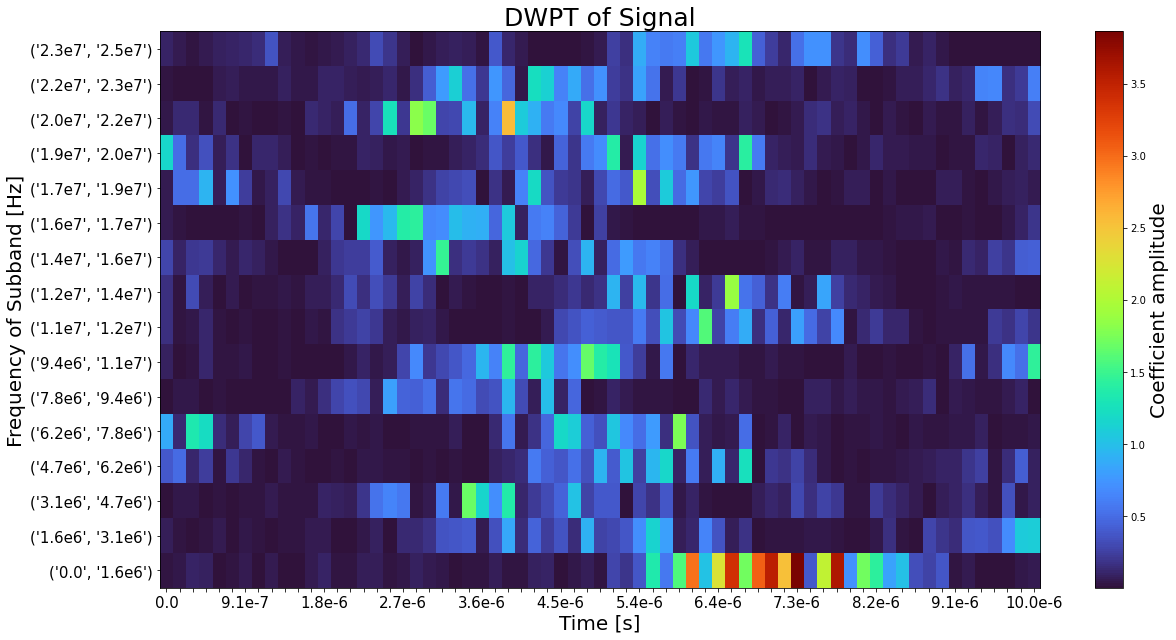

In [7]:
plot.heisenberg(tr_ob, max(t_plot))

## Defining the nodes and edges for the graph representing the WPT

In [8]:
graph_nodes = []
graph_edges = []

for i in range(levels,-1, -1):
    for node in tr_ob.info(level=i, order="natural")["node number"]:
        graph_nodes.append(
            (
                (i, node),
                {"energy": tr_ob.info(level=i, order="natural").loc[node]["energy"]},
            )
        )


        graph_edges.append(((i, node), (i - 1, node // 2)))

Defining an empty graph object with `DiGraph` function:

In [9]:
G = nx.DiGraph()

Adding nodes and edges to the graph object

In [10]:
G.add_nodes_from(graph_nodes)
G.add_edges_from(graph_edges)

Plotting the graph below, using `graphviz_layout` function to format the layout

In [13]:
from networkx.drawing.nx_agraph import graphviz_layout

ImportError: requires pygraphviz http://pygraphviz.github.io/

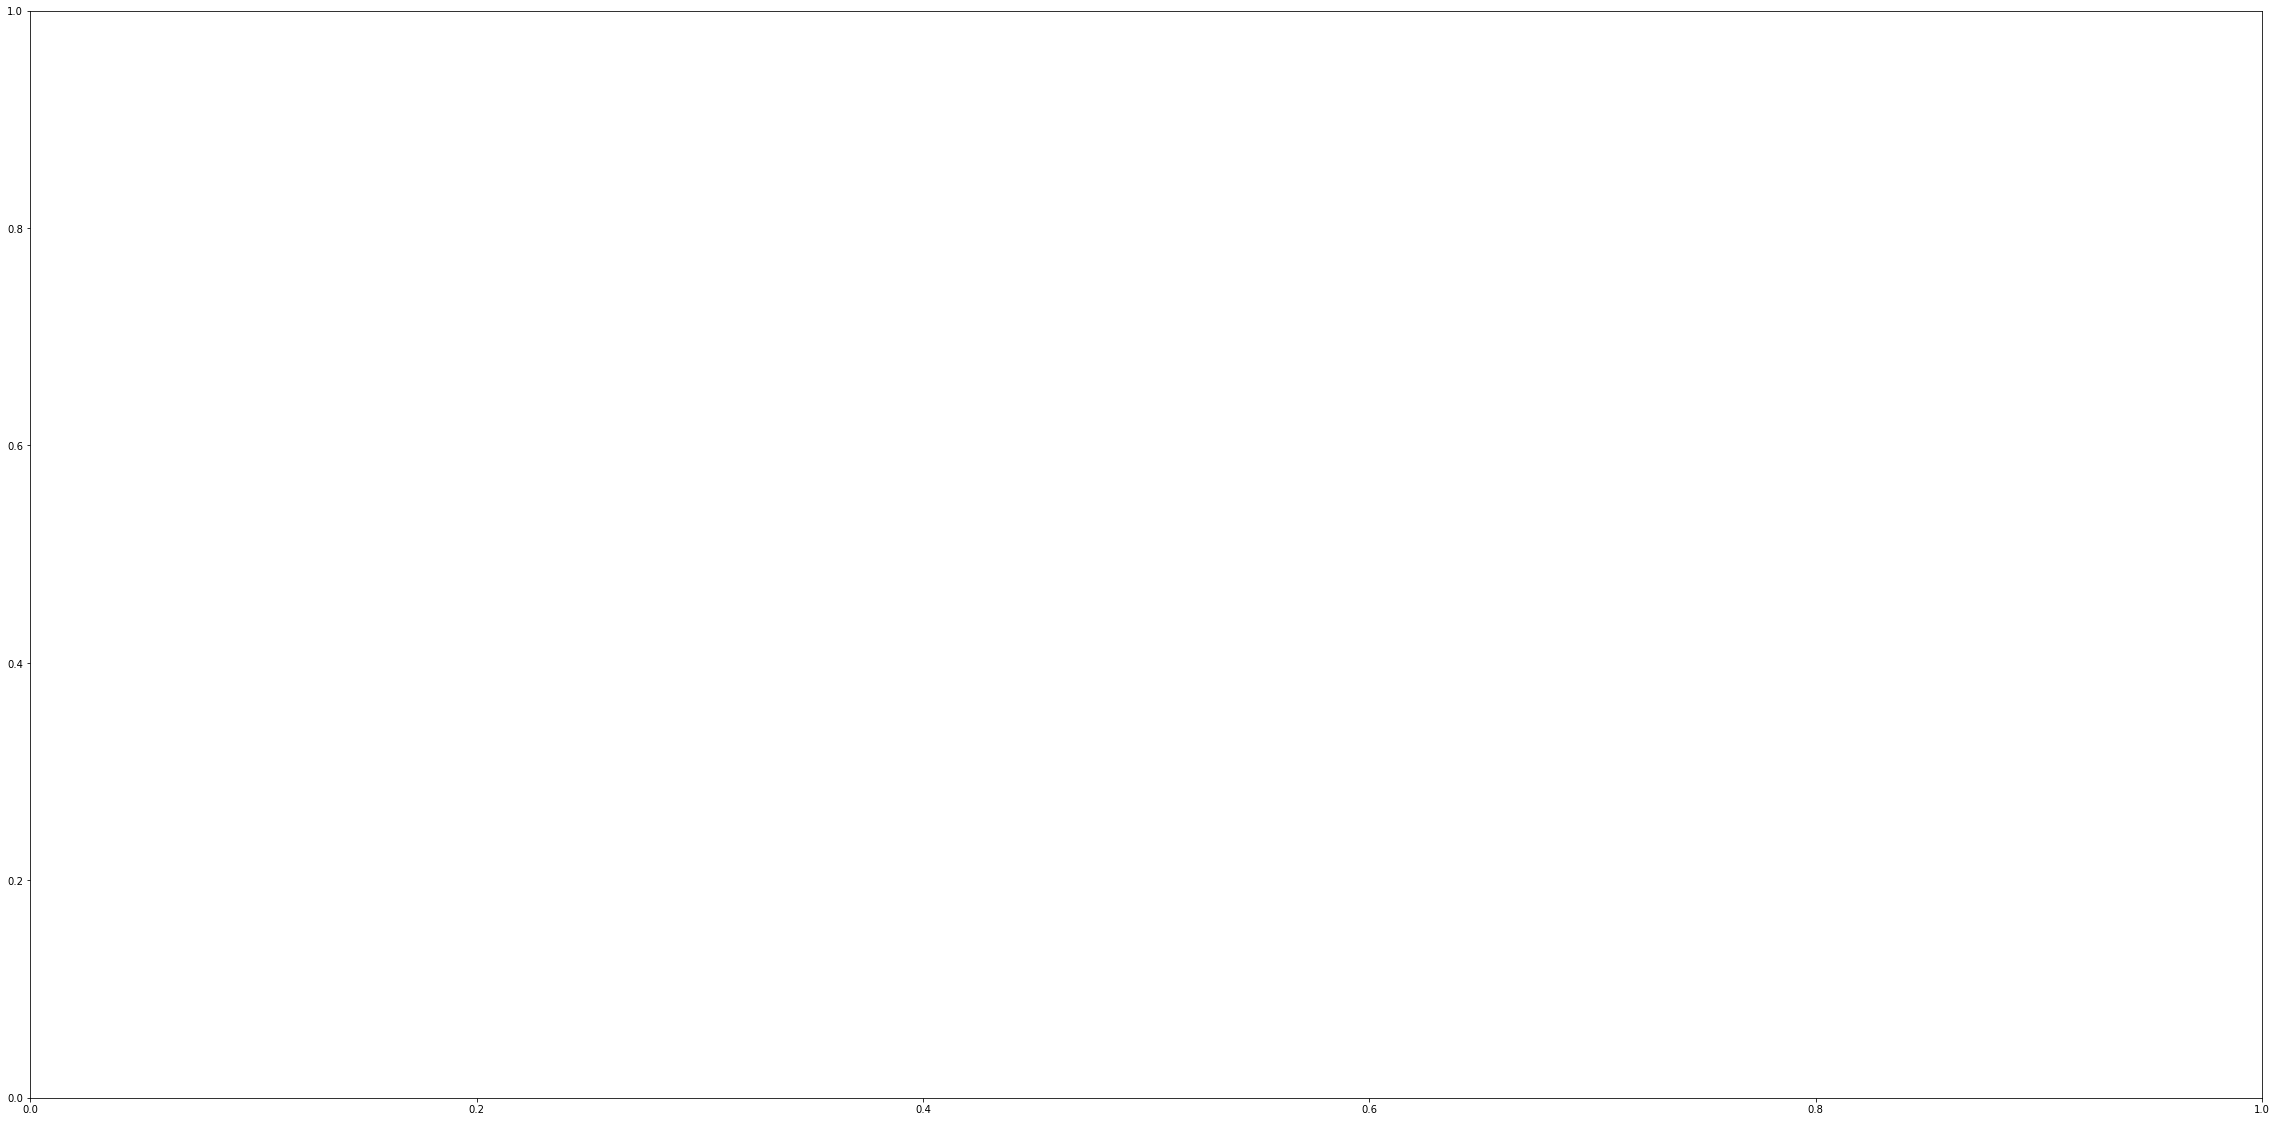

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(40, 20))
nx.draw(
    G,
    pos = graphviz_layout(G,prog = "dot"),
    ax=ax,
    arrowsize=5,
    verticalalignment="top",
    font_size=16,
    font_color="red",
    with_labels=True,
    node_size=1000, node_color="skyblue", node_shape="s", alpha=0.5, linewidths=2,
    width=2, edge_color="green", style="solid"
)  # pos=pos_nodes,
plt.show()

We can reproduce the same graph but weight each node depending on their attributes, e.g. the value of energy at each node

ImportError: requires pygraphviz http://pygraphviz.github.io/

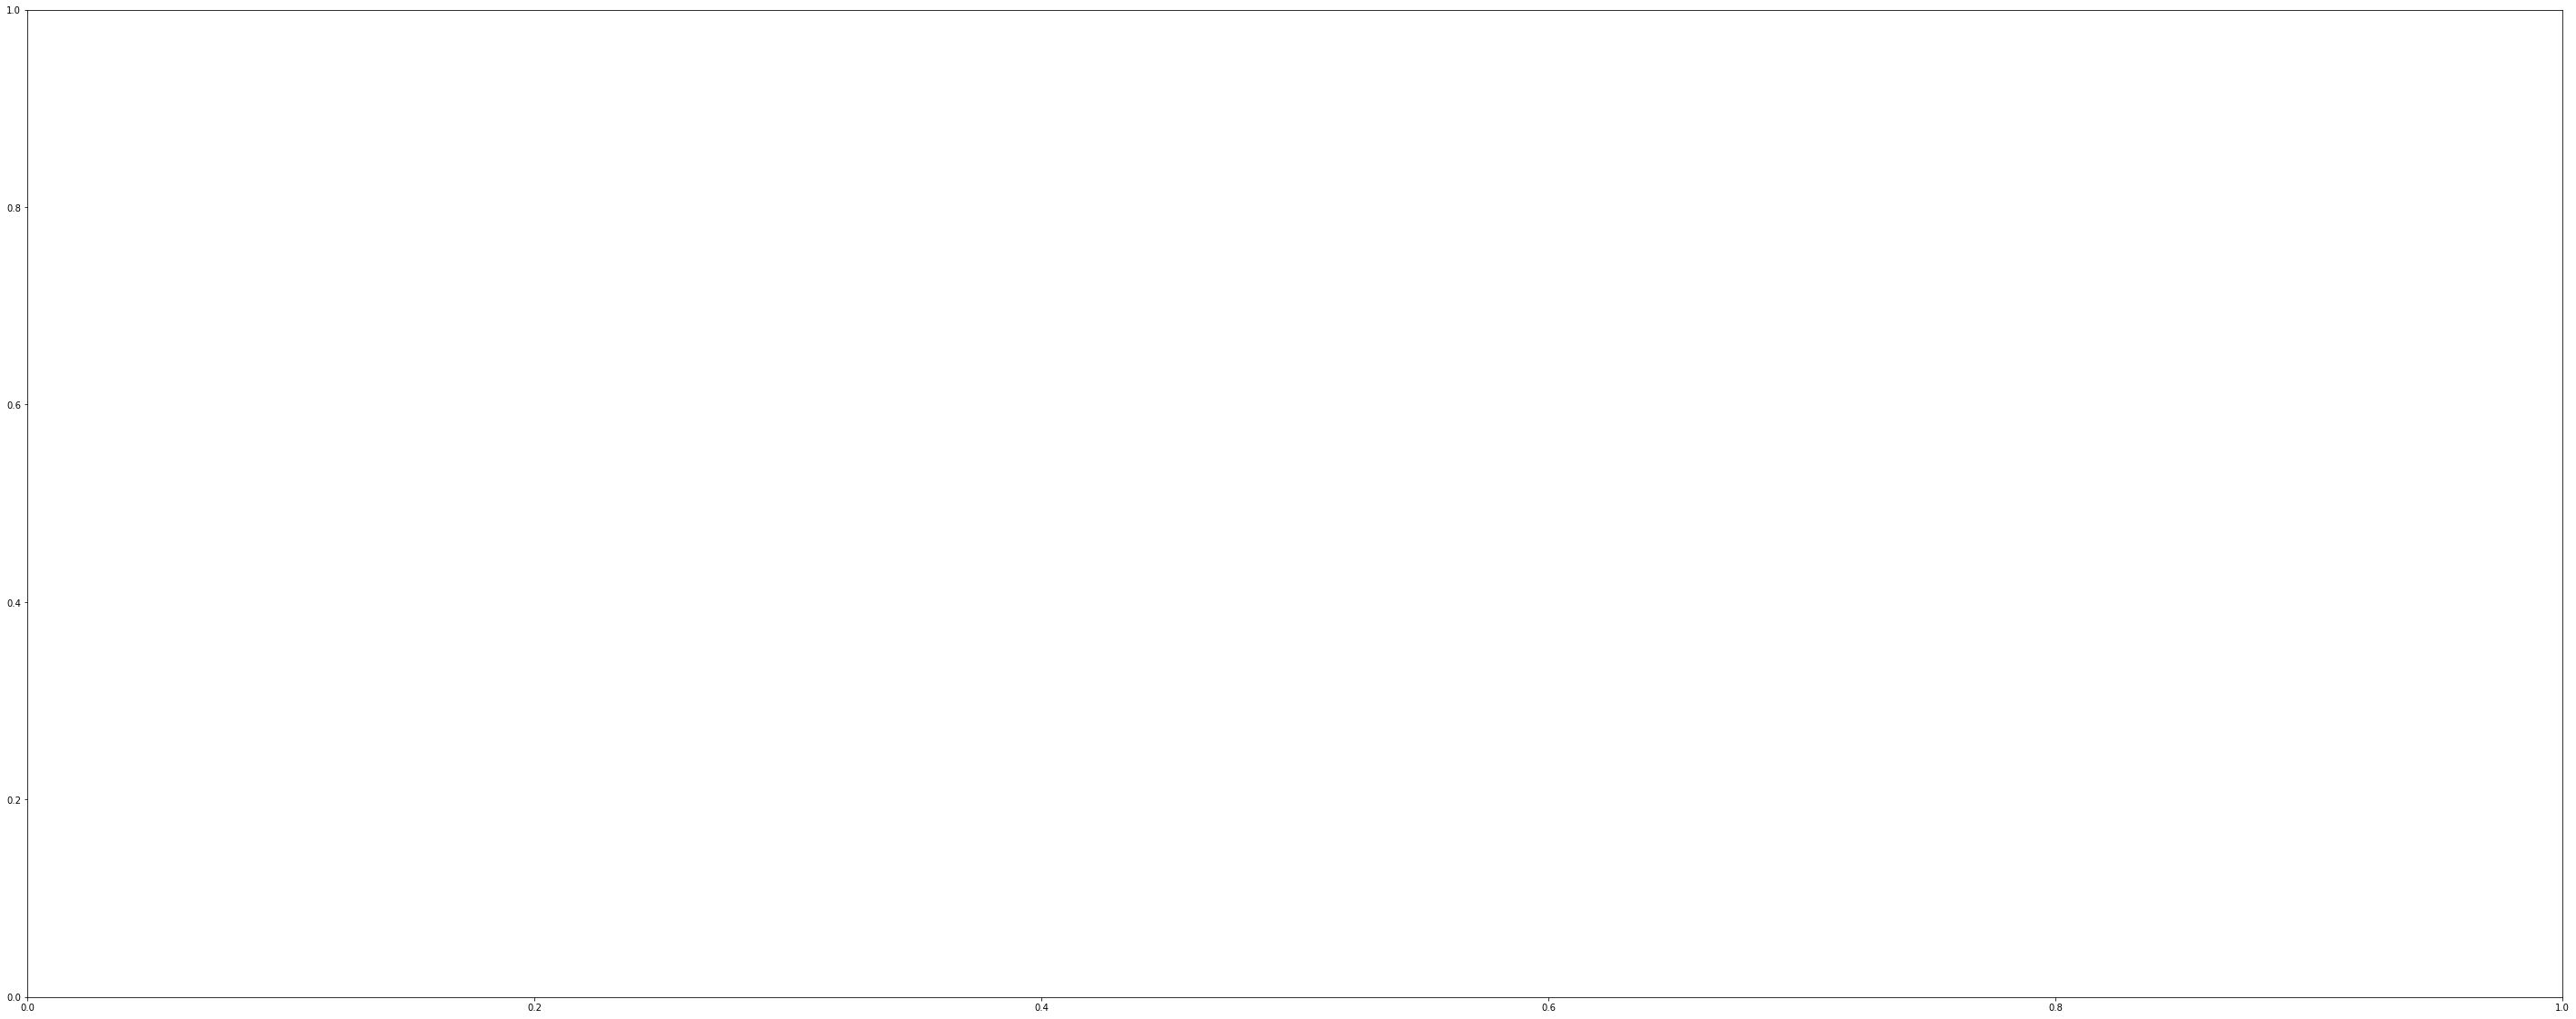

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(50, 20))
nx.draw(
    G,
    pos = graphviz_layout(G,prog = "dot"),
    ax=ax,
    arrowsize=5,
    verticalalignment="bottom",
    font_size=16,
    font_color="red",
    with_labels=True,
    node_size=[1E3*nx.get_node_attributes(G, "energy")[v] for v in G],
    node_color="skyblue", node_shape="s", alpha=0.5, linewidths=2,
    width=2, edge_color="green", style="solid"
)  # pos=pos_nodes,
plt.show()
